# 02 · Cross-validation and evaluation metrics

**Goal:** pick the right split strategy and the right metric, and report results honestly (mean ± std).
**Time:** ~2 hours.

## Split strategies
| Strategy | Use when |
|---|---|
| Hold-out (train/val/test) | Lots of data; final unbiased test score |
| `KFold` | Default for regression |
| `StratifiedKFold` | Classification: keeps class ratio in every fold |
| `GroupKFold` | Several rows per patient/user/customer: the same group must never be in train and test |
| `TimeSeriesSplit` | Time-ordered data: always train on the past, test on the future |

**Golden rule:** the test set is touched **once**, at the very end. Tune on CV folds only.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_diabetes, make_classification
from sklearn.model_selection import (KFold, StratifiedKFold, GroupKFold, TimeSeriesSplit,
                                     train_test_split, cross_validate)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, average_precision_score, RocCurveDisplay,
                             PrecisionRecallDisplay, precision_recall_curve, f1_score,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.calibration import CalibrationDisplay

## 1. See what each splitter does (10 samples, 2 groups of labels)

In [2]:
X_demo = np.arange(10).reshape(-1, 1)
y_demo = np.array([0, 0, 0, 0, 0, 0, 1, 1, 1, 1])
groups = np.array([1, 1, 2, 2, 3, 3, 4, 4, 5, 5])   # e.g. patient id
splitters = {
    "KFold(shuffle)": KFold(3, shuffle=True, random_state=0),
    "StratifiedKFold": StratifiedKFold(3, shuffle=True, random_state=0),
    "GroupKFold": GroupKFold(3),
    "TimeSeriesSplit": TimeSeriesSplit(3),
}
for name, sp in splitters.items():
    print(f"--- {name}")
    for tr, te in sp.split(X_demo, y_demo, groups):
        print("  train", tr, "| test", te, "| test labels", y_demo[te])

--- KFold(shuffle)
  train [0 1 3 5 6 7] | test [2 4 8 9] | test labels [0 0 1 1]
  train [0 2 3 4 5 8 9] | test [1 6 7] | test labels [0 1 1]
  train [1 2 4 6 7 8 9] | test [0 3 5] | test labels [0 0 0]
--- StratifiedKFold
  train [0 1 3 5 6 8] | test [2 4 7 9] | test labels [0 0 1 1]
  train [0 2 4 5 6 7 9] | test [1 3 8] | test labels [0 0 1]
  train [1 2 3 4 7 8 9] | test [0 5 6] | test labels [0 0 1]
--- GroupKFold
  train [0 1 4 5 6 7] | test [2 3 8 9] | test labels [0 0 1 1]
  train [2 3 4 5 8 9] | test [0 1 6 7] | test labels [0 0 1 1]
  train [0 1 2 3 6 7 8 9] | test [4 5] | test labels [0 0]
--- TimeSeriesSplit
  train [0 1 2 3] | test [4 5] | test labels [0 0]
  train [0 1 2 3 4 5] | test [6 7] | test labels [1 1]
  train [0 1 2 3 4 5 6 7] | test [8 9] | test labels [1 1]


## 2. Report mean ± std across folds, for several metrics at once
One number hides variance. Always give the spread across folds.

In [3]:
X, y = load_breast_cancer(return_X_y=True)
X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
res = cross_validate(model, X_trval, y_trval, cv=cv,
                     scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
                     return_train_score=True)
summary = pd.DataFrame({
    k.replace("test_", ""): [res[k].mean(), res[k].std()]
    for k in res if k.startswith("test_")}, index=["mean", "std"]).T
print(summary.round(4))
print("\ntrain vs val accuracy:", res["train_accuracy"].mean().round(4), "vs", res["test_accuracy"].mean().round(4))

             mean     std
accuracy   0.9824  0.0133
precision  0.9831  0.0169
recall     0.9894  0.0227
f1         0.9859  0.0109
roc_auc    0.9945  0.0112

train vs val accuracy: 0.989 vs 0.9824


## 3. Confusion matrix and the four basic metrics
|  | Predicted 0 | Predicted 1 |
|---|---|---|
| **Actual 0** | TN | FP |
| **Actual 1** | FN | TP |

- **Precision** = TP / (TP + FP): of the ones I flagged, how many were right?
- **Recall** (sensitivity) = TP / (TP + FN): of the real positives, how many did I catch?
- **F1** = harmonic mean of precision and recall.
- **Specificity** = TN / (TN + FP).

Note: in this dataset `1 = benign`. We flip it so that `1 = malignant`, the class we care about catching.

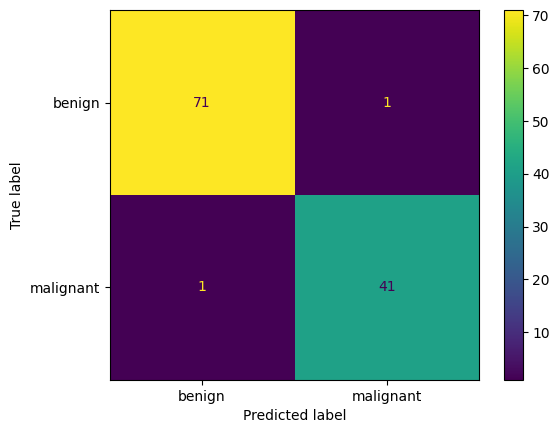

              precision    recall  f1-score   support

      benign      0.986     0.986     0.986        72
   malignant      0.976     0.976     0.976        42

    accuracy                          0.982       114
   macro avg      0.981     0.981     0.981       114
weighted avg      0.982     0.982     0.982       114



In [4]:
y_trval_m, y_test_m = 1 - y_trval, 1 - y_test      # 1 = malignant
model.fit(X_trval, y_trval_m)
proba = model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test_m, pred), display_labels=["benign", "malignant"]).plot()
plt.show()
print(classification_report(y_test_m, pred, target_names=["benign", "malignant"], digits=3))

## 4. Threshold-free metrics: ROC-AUC vs PR-AUC
- **ROC-AUC**: probability that a random positive gets a higher score than a random negative. Insensitive to class balance.
- **PR-AUC (average precision)**: better when positives are **rare**, because it focuses on the positive class.

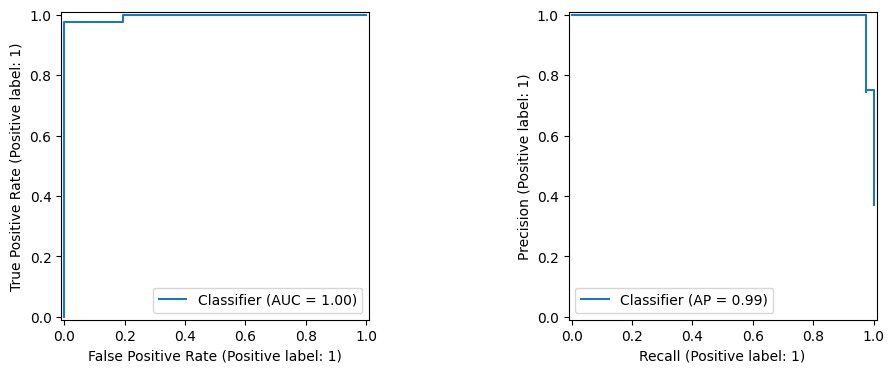

ROC-AUC 0.9954 | PR-AUC 0.994


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_test_m, proba, ax=axes[0])
PrecisionRecallDisplay.from_predictions(y_test_m, proba, ax=axes[1])
plt.show()
print("ROC-AUC", round(roc_auc_score(y_test_m, proba), 4), "| PR-AUC", round(average_precision_score(y_test_m, proba), 4))

## 5. The threshold is a business decision
For cancer screening, missing a malignant case (FN) is far worse than a false alarm (FP).
Pick the threshold that reaches the recall you need **on validation data**, then report test results.

In [6]:
# choose threshold on a validation split, never on the test set
X_tr, X_val, y_tr, y_val = train_test_split(X_trval, y_trval_m, test_size=0.25, stratify=y_trval_m, random_state=0)
model.fit(X_tr, y_tr)
p_val = model.predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, p_val)
target_recall = 0.98
ok = np.where(rec[:-1] >= target_recall)[0]
best_thr = thr[ok[-1]]       # highest threshold that still meets the recall target
print(f"threshold for recall >= {target_recall}: {best_thr:.3f}")

model.fit(X_trval, y_trval_m)
p_test = model.predict_proba(X_test)[:, 1]
for t in [0.5, best_thr]:
    pr = (p_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_m, pr).ravel()
    print(f"t={t:.3f}  recall={tp/(tp+fn):.3f}  precision={tp/(tp+fp):.3f}  FN={fn}  FP={fp}")

threshold for recall >= 0.98: 0.564
t=0.500  recall=0.976  precision=0.976  FN=1  FP=1
t=0.564  recall=0.976  precision=0.976  FN=1  FP=1


## 6. Accuracy paradox on imbalanced data
With 3% positives, a model that always says "negative" gets 97% accuracy and is useless.

In [7]:
Xi, yi = make_classification(n_samples=5000, n_features=20, n_informative=5, weights=[0.97], random_state=1)
print("positive rate:", yi.mean().round(3))
always_neg = np.zeros_like(yi)
print("accuracy of 'always negative':", (always_neg == yi).mean().round(3), "| its recall: 0.0")

m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
for cw in [None, "balanced"]:
    m.set_params(logisticregression__class_weight=cw)
    r = cross_validate(m, Xi, yi, cv=StratifiedKFold(5, shuffle=True, random_state=0),
                       scoring=["accuracy", "recall", "precision", "average_precision"])
    print(f"class_weight={cw!s:9}", {k[5:]: round(v.mean(), 3) for k, v in r.items() if k.startswith("test_")})

positive rate: 0.036
accuracy of 'always negative': 0.964 | its recall: 0.0


class_weight=None      {'accuracy': np.float64(0.972), 'recall': np.float64(0.236), 'precision': np.float64(0.955), 'average_precision': np.float64(0.528)}
class_weight=balanced  {'accuracy': np.float64(0.787), 'recall': np.float64(0.719), 'precision': np.float64(0.112), 'average_precision': np.float64(0.414)}


## 7. Calibration: are the probabilities trustworthy?
If the model says 0.8 for 100 patients, about 80 of them should be positive. Matters whenever probabilities
drive decisions (risk scores, pricing).

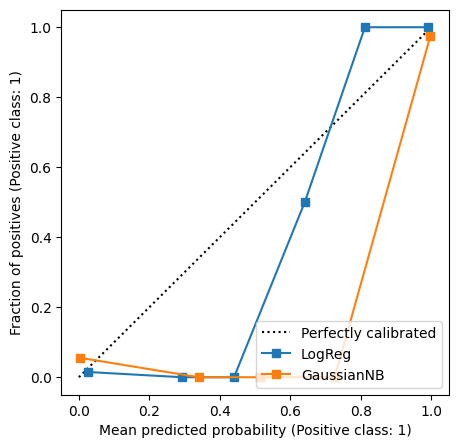

In [8]:
from sklearn.naive_bayes import GaussianNB
fig, ax = plt.subplots(figsize=(5, 5))
for name, est in {"LogReg": model, "GaussianNB": GaussianNB()}.items():
    est.fit(X_trval, y_trval_m)
    CalibrationDisplay.from_estimator(est, X_test, y_test_m, n_bins=6, name=name, ax=ax)
plt.show()

## 8. Regression metrics

In [9]:
Xd, yd = load_diabetes(return_X_y=True)
Xa, Xb, ya, yb = train_test_split(Xd, yd, test_size=0.2, random_state=0)
reg = Ridge(alpha=1.0).fit(Xa, ya)
p = reg.predict(Xb)
print(f"MAE  {mean_absolute_error(yb, p):.1f}   (average absolute error, robust to outliers)")
print(f"RMSE {mean_squared_error(yb, p) ** 0.5:.1f}   (punishes big errors more)")
print(f"R²   {r2_score(yb, p):.3f}  (share of variance explained; 0 = predicting the mean)")

MAE  46.6   (average absolute error, robust to outliers)
RMSE 58.1   (punishes big errors more)
R²   0.341  (share of variance explained; 0 = predicting the mean)


## ✍️ Your turn
1. Repeat section 2 with `KFold` (no stratify) and 3 folds. How much does the std change?
2. For a **spam filter**, which matters more: precision or recall? Pick a threshold with precision ≥ 0.99.
3. Write a function `report(y_true, proba, threshold)` that prints recall, precision, F1, specificity.

## 🎯 Interview check
- When is accuracy a bad metric? What do you use instead?
- ROC-AUC vs PR-AUC: when does the difference matter?
- Why should the threshold be chosen on validation data, not on the test set?
- You have 5 rows per patient. Which CV splitter and why?

In [10]:
# Your code here